# Skewed distributions and the log transform

Many quantities can't go below zero but have no upper limit: incomes, prices, populations, counts. Most values are modest and a few are very large, so their distribution has a long tail to the right: it is **skewed**. Some models are indifferent to that shape; for others, a transformation that pulls the tail in, most often the logarithm, makes the relationship easier to learn. Whether it does is something to check, not to assume.

## A long right tail

The yearly incomes of eight people, in thousands:

In [ ]:
import numpy as np
import pandas as pd

incomes = pd.Series([18, 22, 25, 28, 31, 35, 60, 240], name="income")
pd.Series({"mean": incomes.mean(), "median": incomes.median(), "skewness": incomes.skew()}).round(2)

mean        57.38
median      29.50
skewness     2.67
dtype: float64

The mean, 57, is higher than six of the eight incomes: the tail pulls it. The median, 29.5, stays with the bulk. **Skewness** measures the asymmetry: 0 for a symmetric distribution, positive for a long right tail, negative for a long left one; above 1 in absolute value is usually considered strongly skewed.

(Such distributions are often called *heavy-tailed*. Strictly, that term is about how slowly the tail thins out, and a symmetric distribution can have heavy tails too. What matters here is the asymmetry.)

The natural logarithm of each income:

In [ ]:
pd.DataFrame({"income": incomes, "log": np.log(incomes)}).round(2).T

,0,1,2,3,4,5,6,7
income,18.00,22.00,25.00,28.00,31.00,35.00,60.00,240.00
log,2.89,3.09,3.22,3.33,3.43,3.56,4.09,5.48


The logarithm turns ratios into differences: from 20 to 40 thousand is the same step as from 120 to 240, because both double. So the 240, more than thirteen times the smallest income, is now only 2.6 units above it. Large values are pulled in much more than small ones, and the tail shortens:

In [ ]:
np.log(incomes).skew().round(2)

np.float64(1.91)

Less skewed, though not symmetric: one income more than thirteen times the smallest is extreme even on a logarithmic scale. The logarithm needs positive values; `np.log1p`, the logarithm of $1 + x$, is the usual choice when there are zeros.

## A real column

The California housing data of [Outliers and capped values](outliers.ipynb), without the districts whose value was capped at 500,001 dollars, so that the cap doesn't blur the comparisons, and with the people per household that [Outliers and capped values](outliers.ipynb) looked at:

In [ ]:
from sklearn.model_selection import train_test_split

import tarfile
import urllib.request
from pathlib import Path

housing_csv = Path("data/housing/housing.csv")
if not housing_csv.exists():
    housing_csv.parent.mkdir(parents=True, exist_ok=True)
    archive, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/housing.tgz")
    with tarfile.open(archive) as tar:
        tar.extractall(path="data", filter="data")
housing = pd.read_csv(housing_csv)
housing = housing[housing["median_house_value"] < 500_001].assign(
    people_per_household=lambda frame: frame["population"] / frame["households"])
train, test = train_test_split(housing, test_size=0.2, random_state=42)
len(train)

15740

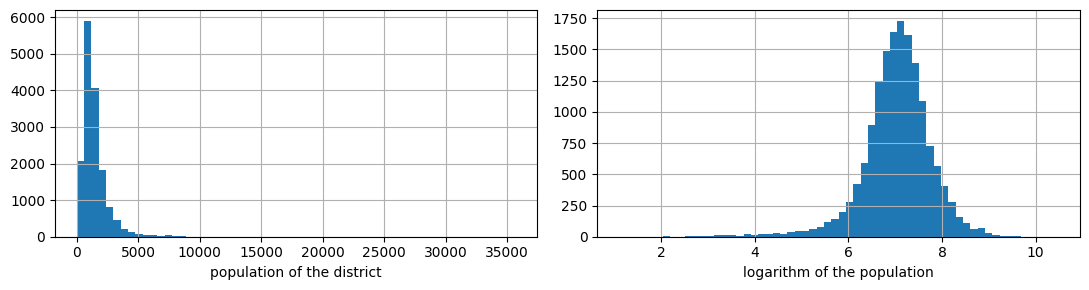

In [ ]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(11, 3))
train["population"].hist(bins=60, ax=axes[0])
axes[0].set_xlabel("population of the district")
np.log(train["population"]).hist(bins=60, ax=axes[1])
axes[1].set_xlabel("logarithm of the population")
figure.tight_layout()

In [ ]:
totals = ["total_rooms", "total_bedrooms", "population", "households"]
pd.DataFrame({"skewness": train[totals].skew(), "skewness of the logarithm": np.log(train[totals]).skew()}).round(2)

,skewness,skewness of the logarithm
total_rooms,4.20,-1.05
total_bedrooms,3.45,-1.03
population,5.36,-1.05
households,3.44,-1.09


The four totals have a long right tail (skewness between 3.4 and 5.4). The logarithm turns them around: they become moderately skewed to the *left* (about −1), because a few very small districts now stand out at the bottom. The logarithm is a strong transformation, and not always the right amount.

## Does the model care?

- **Trees** don't: a tree splits at thresholds, and the logarithm keeps the order of the values, so it keeps the same splits ([Scaling numerical features](../feature_scaling.ipynb) shows the same for scaling).
- **Linear models** fit straight lines. The few values in the tail sit far from the rest and pull the line towards them ([Outliers and capped values](outliers.ipynb)), and many relationships with such quantities are multiplicative (twice as many rooms, about twice as many people) rather than additive, which is what a straight line through logarithms describes.
- **Models built on distances** see the tail as a few points very far from everything else, even after scaling.

People per household against the house value, with the line a linear regression fits to each:

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

people = train[["people_per_household"]]
value = train["median_house_value"]
logarithm = FunctionTransformer(np.log, feature_names_out="one-to-one")
pd.Series({
    "people per household": cross_val_score(LinearRegression(), people, value, cv=5).mean(),
    "its logarithm": cross_val_score(make_pipeline(logarithm, LinearRegression()), people, value, cv=5).mean(),
}).round(3).rename("R², 5-fold cross-validation")

people per household   -0.001
its logarithm           0.053
Name: R², 5-fold cross-validation, dtype: float64

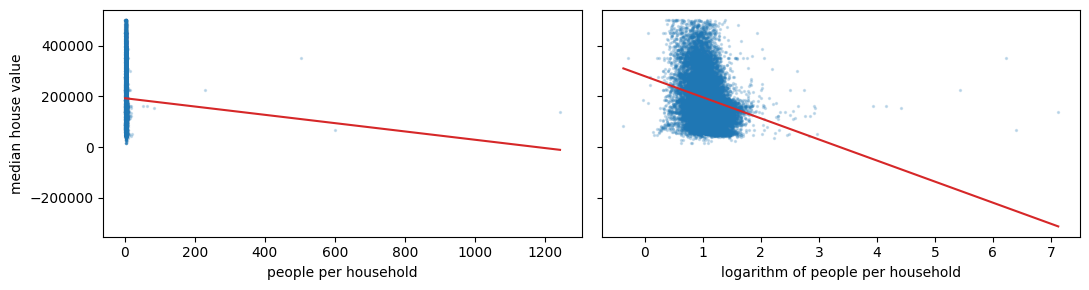

In [ ]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for axis, column in zip(axes, [people["people_per_household"], np.log(people["people_per_household"])]):
    axis.scatter(column, value, s=2, alpha=0.2)
    fitted = LinearRegression().fit(column.to_frame(), value)
    grid = pd.DataFrame({column.name: np.linspace(column.min(), column.max(), 100)})
    axis.plot(grid[column.name], fitted.predict(grid), color="tab:red")
axes[0].set_xlabel("people per household")
axes[1].set_xlabel("logarithm of people per household")
axes[0].set_ylabel("median house value")
figure.tight_layout()

On the raw ratio, almost every district is squeezed against the left edge by a few districts with hundreds of people per household (the prison towns of [Outliers and capped values](outliers.ipynb)), and the line explains nothing (an R² of 0). On the logarithm, the districts spread out, and the line shows a real, if weak, relationship: more people per household, lower values. It explains about 5% of the variance, as a single feature.

But the logarithm is not an improvement by default. A linear regression, k-nearest neighbours and a random forest on the eight numerical features, with the four totals as they are and with their logarithms, by 5-fold cross-validation:

In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

features = ["longitude", "latitude", "housing_median_age", "median_income", *totals]
others = [feature for feature in features if feature not in totals]


def with_totals(transform_totals, model):
    preprocessing = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), transform_totals, StandardScaler()), totals),
        (StandardScaler(), others),
    )
    return make_pipeline(preprocessing, model)


models = {
    "linear regression": LinearRegression(),
    "k-nearest neighbours": KNeighborsRegressor(),
    "random forest": RandomForestRegressor(n_estimators=50, random_state=0, n_jobs=-1),
}
pd.DataFrame({
    "totals as they are": {name: cross_val_score(with_totals("passthrough", model), train[features], value, cv=5).mean()
                           for name, model in models.items()},
    "logarithm of the totals": {name: cross_val_score(with_totals(logarithm, model), train[features], value, cv=5).mean()
                                for name, model in models.items()},
}).round(3)

,totals as they are,logarithm of the totals
linear regression,0.594,0.620
k-nearest neighbours,0.656,0.658
random forest,0.783,0.783


The linear regression gains almost three points of R² (0.594 to 0.620), k-nearest neighbours barely changes, and the random forest gets the same score, as expected of trees. Here the logarithm helps the model that fits straight lines.

It is not a rule, though. Median income is mildly skewed (about 0.9), and its relationship with the value is already close to a straight line. As a single feature, as it is and as a logarithm:

In [ ]:
income = train[["median_income"]]
pd.Series({
    "median income": cross_val_score(LinearRegression(), income, value, cv=5).mean(),
    "its logarithm": cross_val_score(make_pipeline(logarithm, LinearRegression()), income, value, cv=5).mean(),
}).round(3).rename("R², 5-fold cross-validation")

median income    0.412
its logarithm    0.375
Name: R², 5-fold cross-validation, dtype: float64

The logarithm of the income fits worse (0.375 against 0.412): it bends a relationship that was already straight. A transformation is a hypothesis about the shape of a relationship. "Take the logarithm of every skewed column" is a reasonable first guess, to be kept only where validation agrees.

## Other transformations

Two transformers of scikit-learn choose the amount of transformation from the data:

- **`PowerTransformer`** applies a family of power functions, of which the logarithm is one member, and chooses for each column the power that makes it most like a normal distribution: the *Yeo-Johnson* transformation, which accepts any value, or *Box-Cox*, for positive values only. It also standardises the result by default.
- **`QuantileTransformer`** replaces each value by its rank and maps the ranks onto a chosen distribution, uniform or normal. Any shape becomes the chosen one, and extreme values become ordinary ranks; but distances between values are lost, since only their order is kept.

On the population:

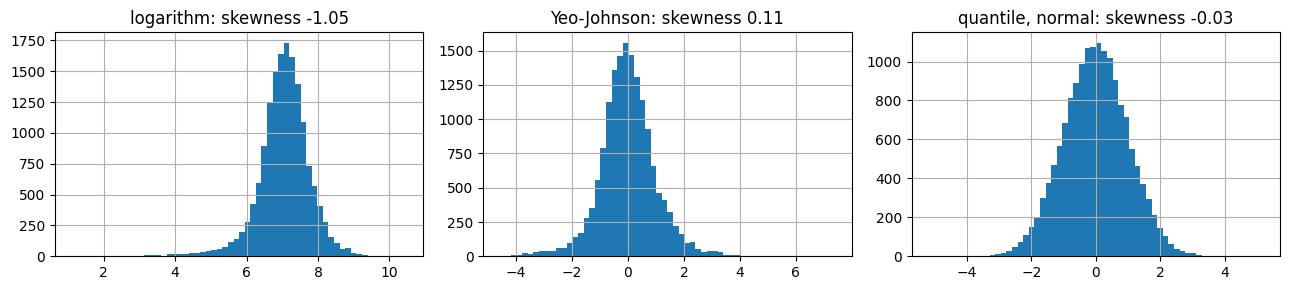

In [ ]:
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

population = train[["population"]]
transformed = {
    "logarithm": np.log(population["population"]),
    "Yeo-Johnson": PowerTransformer().set_output(transform="pandas").fit_transform(population)["population"],
    "quantile, normal": QuantileTransformer(output_distribution="normal", random_state=0).set_output(
        transform="pandas").fit_transform(population)["population"],
}
figure, axes = plt.subplots(1, 3, figsize=(13, 3))
for axis, (name, column) in zip(axes, transformed.items()):
    column.hist(bins=60, ax=axis)
    axis.set_title(f"{name}: skewness {column.skew():.2f}")
figure.tight_layout()

The Yeo-Johnson transformation finds a milder power than the logarithm and gets close to symmetric; the quantile transformation makes the column normal by construction.

Here lies a difference that decides where each transformation goes. The logarithm is a fixed function: it learns nothing from the data and gives the same result whoever applies it, so it can be done once, when the table is built, or inside the pipeline. `PowerTransformer` learns a power for each column, and `QuantileTransformer` learns the quantiles: both are fitted, so they belong in the model's pipeline, fitted on the training rows only ([Where data preparation ends](../where_preparation_ends.ipynb)).

## The logarithm of the target

The target can be transformed too: the model learns to predict the logarithm of the value, and its predictions are turned back with the exponential. `TransformedTargetRegressor` does both. Gradient boosting on the same features, with the value as it is and with its logarithm; the predictions are cross-validated, each one made by a model that didn't see that district:

In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_predict

boosting = HistGradientBoostingRegressor(random_state=0)
predictions = {
    "value as it is": cross_val_predict(boosting, train[features], value, cv=5),
    "logarithm of the value": cross_val_predict(
        TransformedTargetRegressor(regressor=boosting, func=np.log, inverse_func=np.exp), train[features], value, cv=5),
}
pd.DataFrame({
    name: {
        "mean prediction": predicted.mean(),
        "RMSE": np.sqrt(np.mean((predicted - value) ** 2)),
        "mean percentage error": 100 * np.mean(np.abs(predicted - value) / value),
    }
    for name, predicted in predictions.items()
}).round(1)

,value as it is,logarithm of the value
mean prediction,192311.7,187394.4
RMSE,43892.5,44739.3
mean percentage error,17.8,16.6


The actual mean of the values, for comparison:

In [ ]:
value.mean().round(0)

np.float64(192449.0)

Three differences, all of them expected:

- **The errors become relative.** A difference of 0.1 between logarithms is about a 10% error, whatever the value, so the model trained on logarithms cares about percentage errors, and its mean percentage error is lower (16.6% against 17.8%). The squared error, which weighs the expensive districts most, gets slightly worse. Which is better depends on the measure the task needs ([Measuring a regression model's error](../../supervised-learning/evaluation/regression_metrics.ipynb)).
- **The predictions are lower on average:** about 187,000 dollars, while the other model's predictions average about 192,000, like the actual values. Minimising squared errors on logarithms, the model predicts the mean of the logarithms, and the exponential of a mean of logarithms is a *geometric mean*, which is always below the ordinary mean when values vary. The eight incomes show it:

In [ ]:
pd.Series({"mean": incomes.mean(), "exponential of the mean logarithm": np.exp(np.log(incomes).mean()),
           "median": incomes.median()}).round(1)

mean                                 57.4
exponential of the mean logarithm    38.0
median                               29.5
dtype: float64

The geometric mean, 38, lies between the median and the mean. A model of log-values predicts something like a typical value, not an average: right for valuing one district, biased if the predictions are added up (the value of a whole portfolio of districts), where corrections for this bias are needed.
- **The model can't predict zero or a negative value**, since the exponential is always positive: right for prices, and one more reason the logarithm suits them.